# Flower Classification Using a Custom CNN

**CVPR Mid Assignment — CNN Development on Custom Dataset**  
**Student ID:** `23-50074-1`  
**Dataset:** [Flowers Recognition — Kaggle](https://www.kaggle.com/datasets/alxmamaev/flowers-recognition)  

**Objective:** Build and train a simple CNN to classify five types of flowers: daisy, dandelion, rose, sunflower, and tulip.

This notebook follows the structure of our teacher's **Cat and Dog CNN** example. The final sections save and load the model weights, following the teacher's **Model Save and Load** example.


## 1. Import Libraries

In [1]:
# Run once in Google Colab if the packages are not already installed.
%pip -q install kagglehub torchsummary

In [2]:
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import torch
import torch.nn as nn
from torch.optim import Adam
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import kagglehub

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Download the Kaggle Dataset

The Kaggle Flowers Recognition dataset has **five flower classes**. We will download it with `kagglehub`, just as our teacher downloaded the Cat/Dog dataset.

In [3]:
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
folder = path + "/flowers"
print("Dataset folder:", folder)


Using Colab cache for faster access to the 'flowers-recognition' dataset.
Dataset folder: /kaggle/input/flowers-recognition/flowers


## 3. Data Preprocessing and Augmentation

Resize images to **32 × 32**, use small augmentations for training, and convert images into tensors. The validation and test images are **not augmented**.

In [4]:
from torch.utils.data import random_split

size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Use augmentation only for training images.
train_images = datasets.ImageFolder(folder, transform=train_transform)
val_test_images = datasets.ImageFolder(folder, transform=val_transform)

train_size = int(0.8 * len(train_images))
val_size = int(0.1 * len(train_images))
test_size = len(train_images) - train_size - val_size

train_part, val_data, test_data = random_split(
    val_test_images, [train_size, val_size, test_size]
)
train_data = Subset(train_images, train_part.indices)
all_train_images = train_images

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Classes:", train_images.classes)


Train: 3453
Validation: 431
Test: 433
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


## 4. Hyperparameters and DataLoaders

- **Batch size 32:** Process images in small groups.
- **Learning rate 0.001:** Standard simple starting point for Adam.
- **10 epochs:** Follow the teacher’s example. Increase only if necessary after examining the results.

In [5]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 10

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 5. Define the Custom CNN

Same simple architecture as the teacher’s Cat/Dog example. The only required change is the **last layer: 5 outputs instead of 2**, because this Kaggle dataset has five classes.

In [6]:
def get_model():
    model = nn.Sequential(
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer


## 6. Training and Validation Functions

`train_one_epoch()` updates the model weights. `validation()` checks performance without changing the weights.

In [7]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

## 7. CNN Model Summary

Show the output shape and parameter count of every layer.

In [8]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 5]           1,285
Total params: 1,256,837
Trainable params: 1,256,837
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

## 8. Main Training Loop

Run 10 epochs. At the end of each epoch, record training and validation loss/accuracy.

In [9]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.3219 | Train Accuracy: 41.47% | Val Loss: 1.1837 | Val Accuracy: 49.42%
Epoch [2/10] | Train Loss: 1.0854 | Train Accuracy: 56.33% | Val Loss: 1.0270 | Val Accuracy: 56.61%
Epoch [3/10] | Train Loss: 1.0047 | Train Accuracy: 60.73% | Val Loss: 0.9993 | Val Accuracy: 59.63%
Epoch [4/10] | Train Loss: 0.9551 | Train Accuracy: 61.63% | Val Loss: 0.9979 | Val Accuracy: 60.56%
Epoch [5/10] | Train Loss: 0.9160 | Train Accuracy: 63.63% | Val Loss: 0.9074 | Val Accuracy: 65.66%
Epoch [6/10] | Train Loss: 0.8724 | Train Accuracy: 65.57% | Val Loss: 0.9475 | Val Accuracy: 61.95%
Epoch [7/10] | Train Loss: 0.8503 | Train Accuracy: 66.78% | Val Loss: 0.9088 | Val Accuracy: 63.81%
Epoch [8/10] | Train Loss: 0.8083 | Train Accuracy: 68.03% | Val Loss: 0.9165 | Val Accuracy: 66.59%
Epoch [9/10] | Train Loss: 0.7886 | Train Accuracy: 70.06% | Val Loss: 0.8484 | Val Accuracy: 64.73%
Epoch [10/10] | Train Loss: 0.7377 | Train Accuracy: 71.88% | Val Loss: 0.8486 | Val Accura

## 9. Training and Validation Graphs

These two plots show how loss and accuracy change across epochs.

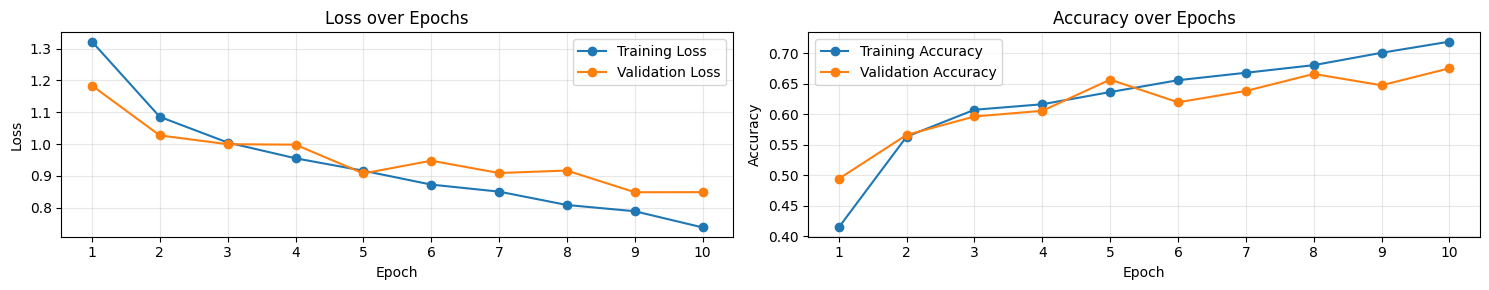

In [10]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))

plt.subplot(121)
plt.title("Loss over Epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Predict One Test Image

Display one flower image, its predicted class, and the predicted probability (confidence).

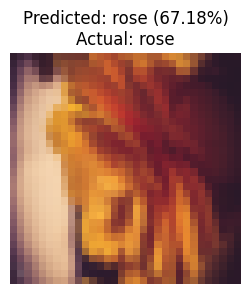

In [11]:
model.eval()
test_img, actual_label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

with torch.no_grad():
    output = model(img)
    pred = torch.softmax(output, dim=1)
    confidence, index = pred.max(-1)

predicted_class = all_train_images.classes[index.item()]
actual_class = all_train_images.classes[actual_label]

plt.figure(figsize=(3, 3))
plt.imshow(test_img.permute(1, 2, 0))
plt.title(f"Predicted: {predicted_class} ({confidence.item()*100:.2f}%)\nActual: {actual_class}")
plt.axis('off')
plt.show()

## 11. Evaluate on the Test Set

Evaluate on held-out test images. Test accuracy is the percentage of correctly classified test images.

In [12]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

Test Loss: 0.8202 | Test Accuracy: 67.44%


## 12. Save the Trained Model

Follow the teacher’s Model Save and Load notebook: save the trained weights as a `.pth` file.

In [13]:
torch.save(model.state_dict(), "flower_cnn_model.pth")
print("Saved model weights to flower_cnn_model.pth")

Saved model weights to flower_cnn_model.pth


## 13. Load the Saved Model and Verify

Create the same CNN architecture and load the saved weights. Use `map_location=device` to work with CPU or GPU.

In [14]:
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load("flower_cnn_model.pth", map_location=device, weights_only=True))
saved_model.eval()

# Check that the loaded model gives the same result as the trained model.
model.eval()
with torch.no_grad():
    original_prediction = model(img)
    loaded_prediction = saved_model(img)

print("Predictions match:", torch.allclose(original_prediction, loaded_prediction))

Predictions match: True


## 14. Analysis and Discussion

The custom CNN was trained for 10 epochs using the Kaggle Flowers Recognition dataset, which contains five flower classes: daisy, dandelion, rose, sunflower, and tulip.

The model achieved the following training and validation results:

| Metric | Result |
|---|---|
| Final Training Accuracy | 71.88% |
| Final Validation Accuracy | 67.52% |
| Final Training Loss | 0.7377 |
| Final Validation Loss | 0.8486 |
| Total Epochs | 10 |

**Training Performance:** The training accuracy increased from 41.47% in the first epoch to 71.88% in the final epoch. Similarly, the training loss decreased from 1.3219 to 0.7377. This indicates that the CNN gradually learned useful visual features from the flower images.

**Validation Performance:** The validation accuracy improved from 49.42% to 67.52%, while the validation loss decreased from 1.1837 to 0.8486. Although there were some fluctuations between epochs, the overall results showed an improvement in classification performance.

**Model Performance:** The final training accuracy was slightly higher than the validation accuracy, with a difference of 4.36 percentage points. This indicates a small generalization gap, but the results do not suggest severe overfitting.

**Overall Analysis:** Both training and validation accuracy increased, while the corresponding losses generally decreased throughout the 10 epochs. These results indicate that the custom CNN successfully learned useful features for flower classification and demonstrated reasonable performance on unseen validation images.

## 15. Conclusion and Future Work

### Conclusion

In this assignment, a custom Convolutional Neural Network (CNN) was developed to classify five types of flowers using the Kaggle Flowers Recognition dataset.

The model used two convolutional layers, ReLU activation functions, MaxPooling, and fully connected layers. Adam was used as the optimizer, and CrossEntropyLoss was used to calculate classification errors.

After training for 10 epochs, the model achieved **71.88% training accuracy, 67.52% validation accuracy, and 67.44% test accuracy**.

The results show that the CNN successfully learned useful visual features from the flower images. The training and validation graphs also showed an overall improvement in model performance.

The trained model weights were successfully saved and loaded for future use.

### Future Work

The model's performance could be improved by:

1. **Increasing image resolution:** Using larger images, such as 64 × 64, may help the CNN identify more detailed flower features.
2. **Training for more epochs:** Additional training may improve accuracy, with validation performance monitored to avoid overfitting.
3. **Adjusting hyperparameters:** Experimenting with different learning rates and batch sizes may improve training performance.
4. **Improving data augmentation:** Additional image transformations may help the model generalize better to unseen images.

Overall, this project demonstrates the basic process of developing, training, evaluating, and saving a custom CNN for image classification.

## Submission Checklist

- [x] Replaced the Student ID in the notebook title and saved it as `CNN_23-50074-1.ipynb`, following the assignment's required naming format (`CNN_StudetID.ipynb`).
- [x] Ran all cells and included the training outputs, model summary, plots, and test results.
- [x] Completed the Analysis and Conclusion sections using the actual experimental results.
- [x] Uploaded the `.ipynb` file to GitHub along with the dataset source link.
- [x] Uploaded `flower_cnn_model.pth` to GitHub, as the model size was under the assignment's 20 MB limit.
- [x] Submitted the notebook copy and GitHub repository link through the teacher's submission form.

**Dataset Credit:** Alexander Mamaev, [Flowers Recognition Dataset (Kaggle)](https://www.kaggle.com/datasets/alxmamaev/flowers-recognition). The dataset's usage terms were reviewed before redistribution.